# 04 — Model Training and Evaluation (Task 4)

This notebook trains and evaluates the three models of the authentication system and explains how they are combined:

| Model | Question it answers | Input |
|---|---|---|
| **Facial recognition** | Which team member is this, and is the match confident enough? | `data/image_features.csv` (96 colour-histogram features) |
| **Voiceprint verification** | Is the voice the *same* member as the face? | `data/audio_features.csv` (36 acoustic features) |
| **Product recommendation** | Which product category will this customer buy? | `data/merged_customer_data.csv` (8 social-media features) |

For every model we compare **Logistic Regression, Random Forest and XGBoost** against a no-skill **baseline** (always predicting the class frequencies), and report:

- **Accuracy**: share of correct predictions.
- **Macro F1-score**: F1 averaged over classes, so every member / category counts equally.
- **Log loss** (cross-entropy): penalises confident wrong predictions; lower is better. The baseline's log loss is the reference for "no information".

All training code lives in `src/` (`python -m src.train_all` reproduces every number and model below); this notebook calls it and adds the analysis.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from scipy.stats import kruskal
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.pipeline import make_pipeline

from src import train_all
from src.config import DATA_DIR, FIGURES_DIR, METRICS_CSV
from src.features import (AUDIO_FEATURE_COLUMNS, IMAGE_FEATURE_COLUMNS,
                          extract_audio_features, extract_image_features, load_audio)
from src.inference import load_artifacts, run_transaction

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.precision", 4)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Chart style: validated categorical palette (colour-blind safe), recessive axes and grid
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
ALGORITHM_COLORS = {"Baseline (class prior)": AXIS, "Logistic Regression": "#2a78d6",
                    "Random Forest": "#eb6834", "XGBoost": "#1baf7a"}
GENUINE_COLOR, IMPOSTOR_COLOR = "#2a78d6", "#eb6834"
SEQUENTIAL = LinearSegmentedColormap.from_list("blue", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#104281"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "text.color": INK, "font.size": 10, "legend.frameon": False,
})

## 2. Feature extraction consistency

At prediction time (the command-line demo) a new photo or voice sample must be described by **exactly the same features** the models were trained on. `src/features.py` re-implements the feature engineering of notebooks 02 and 03; here we re-extract the features of every original photo and recording in `data/` and compare them with the training CSVs.

In [2]:
images = pd.read_csv(DATA_DIR / "image_features.csv")
audio = pd.read_csv(DATA_DIR / "audio_features.csv")

rows = []
for _, r in images[images["augmentation"] == "original"].iterrows():
    new = extract_image_features(DATA_DIR / "images" / r.member / f"{r.member}_{r.expression}.jpg").iloc[0].to_numpy()
    rows.append({"sample": f"{r.member} / {r.expression}", "type": "image",
                 "max difference": np.abs(new - r[IMAGE_FEATURE_COLUMNS].to_numpy(float)).max()})
for _, r in audio[audio["augmentation"] == "original"].iterrows():
    n = 1 if r.original_filename.startswith("First") else 2
    path = DATA_DIR / "audio" / r.speaker / f"{r.speaker}_recording{n}.m4a"
    new = extract_audio_features(path).iloc[0].to_numpy()
    ref = r[AUDIO_FEATURE_COLUMNS].to_numpy(float)
    rows.append({"sample": f"{r.speaker} / recording {n}", "type": "audio (relative)",
                 "max difference": (np.abs(new - ref) / (np.abs(ref) + 1e-9)).max()})
consistency = pd.DataFrame(rows)
display(consistency.style.format({"max difference": "{:.1e}"}).hide(axis="index"))
print("All features reproduced:", bool((consistency["max difference"] < 1e-4).all()))

sample,type,max difference
Janviere / neutral,image,4.8e-09
Janviere / smiling,image,4.7e-09
Janviere / surprised,image,4.1e-09
Josue / neutral,image,6.2e-09
Josue / smiling,image,4.5e-09
Josue / surprised,image,4.4e-09
Thomas / neutral,image,4.2e-09
Thomas / smiling,image,4.8e-09
Thomas / surprised,image,3.9e-09
Yohan / neutral,image,4.2e-09


All features reproduced: True


Every image feature is reproduced to within about 1e-8 and every audio feature to within about 1e-5 (relative), i.e. floating-point rounding. The models will therefore see identical inputs whether a sample comes from the training CSV or is captured live in the demo.

## 3. Training and evaluation

`train_all.run_all()` trains every algorithm for every model, evaluates them, selects one per model, retrains it on all the data and saves it to `models/`. The evaluation designs were chosen so that **the test data is always something the model has never seen**:

| Model | Main evaluation | Comparison with the original notebook |
|---|---|---|
| Face | **Leave-one-expression-out CV**: train on two expressions of every member, test on the third (3 folds, all 48 images tested once) | Hold-out on the *surprised* photos, as in notebook 02 |
| Voice | **Leave-one-recording-out CV**: a recording and all its augmented versions are held out together (8 folds) | Train on first recordings, test on the original second recordings, as in notebook 03 |
| Product | **Customer-grouped, stratified 5-fold CV**: all purchases of a customer are in the same fold | The first fold is exactly the test split of notebook 01 |

For face and voice we also run an **open-set test**, because a real authentication system must reject people it has never seen: each member is removed from training in turn and presented as an unknown user. The highest probability the model gives such a stranger is compared with the probabilities it gives genuine (held-out) samples, and the **confidence threshold** is set where the false-acceptance rate (FAR) plus false-rejection rate (FRR) is lowest. A genuine attempt counts as accepted only if the person is identified correctly *and* the confidence reaches the threshold.

**Model selection:** face and voice pick the algorithm with the lowest open-set error (FAR + FRR), then the highest macro F1 and lowest log loss; the product model picks the highest macro F1, then the lowest log loss.

In [3]:
results = train_all.run_all(verbose=False)
metrics = results["metrics"]
display(results["selected"].style.hide(axis="index"))

model,selected_algorithm
Face recognition,Random Forest
Voiceprint verification,Logistic Regression
Product recommendation,Random Forest


## 4. Facial recognition model

In [4]:
def metric_table(model_name):
    table = metrics[metrics["model"] == model_name].pivot(index="algorithm", columns="evaluation",
                                                          values=["accuracy", "f1_macro", "log_loss"])
    return table.swaplevel(axis=1).sort_index(axis=1, level=0)

display(metric_table("Face recognition").round(3))
display(results["face"]["open_set"].round(3).style.hide(axis="index"))

evaluation             Hold-out: surprised expression (16 images)           \
                                                         accuracy f1_macro   
algorithm                                                                    
Baseline (class prior)                                      0.250    0.100   
Logistic Regression                                         0.812    0.782   
Random Forest                                               1.000    1.000   
XGBoost                                                     0.562    0.448   

evaluation                      Leave-one-expression-out CV (48 images)  \
                       log_loss                                accuracy   
algorithm                                                                 
Baseline (class prior)    1.386                                   0.250   
Logistic Regression       0.235                                   0.938   
Random Forest             0.364                                   1.000   
XGBoost                   0.709                                   0.833   

evaluation                                
                       f1_macro log_loss  
algorithm                                 
Baseline (class prior)    0.100    1.386  
Logistic Regression       0.937    0.083  
Random Forest             1.000    0.225  
XGBoost                   0.830    0.453

algorithm,threshold,FAR,FRR,open_set_error
Logistic Regression,1.000000,0.000000,1.000000,1.000000
Random Forest,0.850000,0.000000,0.271000,0.271000
XGBoost,0.412000,0.625000,0.208000,0.833000


**Closed-set results.** Random Forest identifies every held-out photo correctly in both evaluations (accuracy and macro F1 = 1.00; log loss 0.23 in cross-validation, 0.36 on the *surprised* hold-out, in line with notebook 02). Logistic Regression reaches 0.94 accuracy with the lowest log loss (0.08) but drops to 0.81 on the surprised photos; XGBoost is clearly weaker (0.83 / 0.56), as boosting has very little to learn from with 32 training images per fold. All three are far above the baseline (0.25 accuracy, log loss 1.39).

**Open-set results.** This is where the algorithms really differ. Logistic Regression is *over-confident on strangers*: unknown faces get probabilities as high as genuine ones, so the only way to stop them is a threshold of 1.00, which rejects every genuine user too (FRR = 1.00). XGBoost accepts 62.5% of strangers at its best threshold. Random Forest spreads its probability over several members when it sees an unknown face, so a threshold of **0.85** rejects **every** stranger (FAR = 0%) while accepting 73% of genuine photos of a new expression (FRR = 27%).

→ **Random Forest is selected**, with a confidence threshold of 0.85.

*Caution:* colour histograms describe the whole picture, including background and clothing, and each member was photographed in one setting. The perfect closed-set score partly reflects those settings, which is exactly why the open-set threshold matters.

## 5. Voiceprint verification model

In [5]:
display(metric_table("Voiceprint verification").round(3))
display(results["voice"]["open_set"].round(3).style.hide(axis="index"))

evaluation             Hold-out: second recordings (4 original clips)  \
                                                             accuracy   
algorithm                                                               
Baseline (class prior)                                           0.25   
Logistic Regression                                              1.00   
Random Forest                                                    1.00   
XGBoost                                                          0.75   

evaluation                                \
                       f1_macro log_loss   
algorithm                                  
Baseline (class prior)    0.100    1.386   
Logistic Regression       1.000    0.072   
Random Forest             1.000    0.555   
XGBoost                   0.667    0.606   

evaluation             Leave-one-recording-out CV: all versions (32)           \
                                                            accuracy f1_macro   
algorithm                                                                       
Baseline (class prior)                                         0.000    0.000   
Logistic Regression                                            0.906    0.903   
Random Forest                                                  0.938    0.937   
XGBoost                                                        0.625    0.632   

evaluation                       \
                       log_loss   
algorithm                         
Baseline (class prior)    1.946   
Logistic Regression       0.244   
Random Forest             0.691   
XGBoost                   0.727   

evaluation             Leave-one-recording-out CV: original clips (8)  \
                                                             accuracy   
algorithm                                                               
Baseline (class prior)                                          0.000   
Logistic Regression                                             0.875   
Random Forest                                                   1.000   
XGBoost                                                         0.625   

evaluation                                
                       f1_macro log_loss  
algorithm                                 
Baseline (class prior)    0.000    1.946  
Logistic Regression       0.867    0.241  
Random Forest             1.000    0.630  
XGBoost                   0.642    0.745

algorithm,threshold,FAR,FRR,open_set_error
Logistic Regression,0.830000,0.250000,0.250000,0.500000
Random Forest,0.567000,0.125000,0.656000,0.781000
XGBoost,0.970000,0.000000,1.000000,1.000000


**Closed-set results.** On recordings it has never heard, Logistic Regression identifies 7 of the 8 original clips (accuracy 0.875) and 29 of the 32 clips including augmented versions (0.906), with a low log loss (0.24). On the hold-out of notebook 03 it identifies all four second recordings with log loss 0.07. Random Forest gets one more clip right (all 8 originals, 0.94 on all versions), but its probabilities are much less sharp (log loss 0.63–0.69). XGBoost is again the weakest (0.63). The baseline scores 0 here because, in each fold, the held-out speaker has only one recording left in training, so the "most frequent class" is always somebody else.

**Open-set results.** Logistic Regression separates genuine and unknown voices best: with a threshold of **0.83** it accepts 25% of strangers and rejects 25% of genuine clips. Random Forest would need a threshold of 0.57, which still accepts 12.5% of strangers while rejecting 66% of genuine clips; XGBoost cannot separate them at all.

→ **Logistic Regression is selected** (as in notebook 03), with a confidence threshold of 0.83. Voice alone is a weaker check than face: this is why it is used as a *second* factor that must agree with the face.

## 6. Product recommendation model

In [6]:
display(metric_table("Product recommendation").round(3))

evaluation             Customer-grouped 5-fold CV (150 transactions)           \
                                                            accuracy f1_macro   
algorithm                                                                       
Baseline (class prior)                                         0.227    0.110   
Logistic Regression                                            0.167    0.140   
Random Forest                                                  0.213    0.178   
XGBoost                                                        0.193    0.165   

evaluation                       \
                       log_loss   
algorithm                         
Baseline (class prior)    1.602   
Logistic Regression       1.831   
Random Forest             1.871   
XGBoost                   2.229   

evaluation             Hold-out: notebook 01 test split (31 transactions)  \
                                                                 accuracy   
algorithm                                                                   
Baseline (class prior)                                              0.226   
Logistic Regression                                                 0.161   
Random Forest                                                       0.194   
XGBoost                                                             0.194   

evaluation                                
                       f1_macro log_loss  
algorithm                                 
Baseline (class prior)    0.074    1.603  
Logistic Regression       0.110    1.771  
Random Forest             0.150    1.846  
XGBoost                   0.120    2.055

None of the algorithms beats the baseline in a meaningful way. Random Forest has the best macro F1 (0.18 vs 0.11 for the baseline, which only ever predicts one category), but its accuracy (0.21) is slightly *below* always predicting the most common category (0.23), and every model has a worse log loss than the baseline (1.83–2.23 vs 1.60). On the test split of notebook 01, Random Forest reaches 0.194 accuracy, the same as the tuned Logistic Regression there. Before blaming the models, we check whether the data contains any signal at all:

In [7]:
merged = pd.read_csv(DATA_DIR / "merged_customer_data.csv", parse_dates=["purchase_date"])
merged["month"] = merged["purchase_date"].dt.month
merged["weekday"] = merged["purchase_date"].dt.day_of_week
columns = ["purchase_amount", "customer_rating", "month", "weekday", "avg_engagement_score",
           "avg_purchase_interest_score", "social_record_count", "platform_count",
           "sentiment_Negative", "sentiment_Neutral", "sentiment_Positive"]

# Does each column differ between the five product categories? (Kruskal-Wallis test)
tests = pd.DataFrame([{"column": c, "p_value": kruskal(*[g[c].dropna() for _, g in merged.groupby("product_category")]).pvalue}
                      for c in columns])
tests["significant after Bonferroni (p < 0.05/11)"] = tests["p_value"] < 0.05 / len(columns)
display(tests.round(3).style.hide(axis="index"))

# Even a model given every column, including the post-purchase ones excluded from the product model
splits = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
rf = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(n_estimators=300, random_state=42))
score = cross_val_score(rf, merged[columns + ["has_social_profile"]], merged["product_category"],
                        groups=merged["customer_id_key"], cv=splits).mean()
print(f"Random Forest on ALL columns: accuracy {score:.3f}  (chance 0.200, most frequent category 0.233)")

column,p_value,significant after Bonferroni (p < 0.05/11)
purchase_amount,0.349000,False
customer_rating,0.639000,False
month,0.045000,False
weekday,0.030000,False
avg_engagement_score,0.725000,False
avg_purchase_interest_score,0.068000,False
social_record_count,0.175000,False
platform_count,0.520000,False
sentiment_Negative,0.771000,False
sentiment_Neutral,0.129000,False


Random Forest on ALL columns: accuracy 0.241  (chance 0.200, most frequent category 0.233)


No column differs significantly between product categories once we account for testing eleven columns (the two date columns at p ≈ 0.03–0.05 are within what chance produces over eleven tests), and even a model given every column, including the purchase amount, rating and date that the product model deliberately excludes, only reaches 0.24 accuracy. **The dataset itself contains no learnable relationship between customers and product categories**, so near-chance performance is the correct, honest result rather than a modelling failure.

→ **Random Forest is selected** (highest macro F1) so that the pipeline is complete, but its recommendation should be presented as a low-confidence suggestion.

## 7. Visual comparison

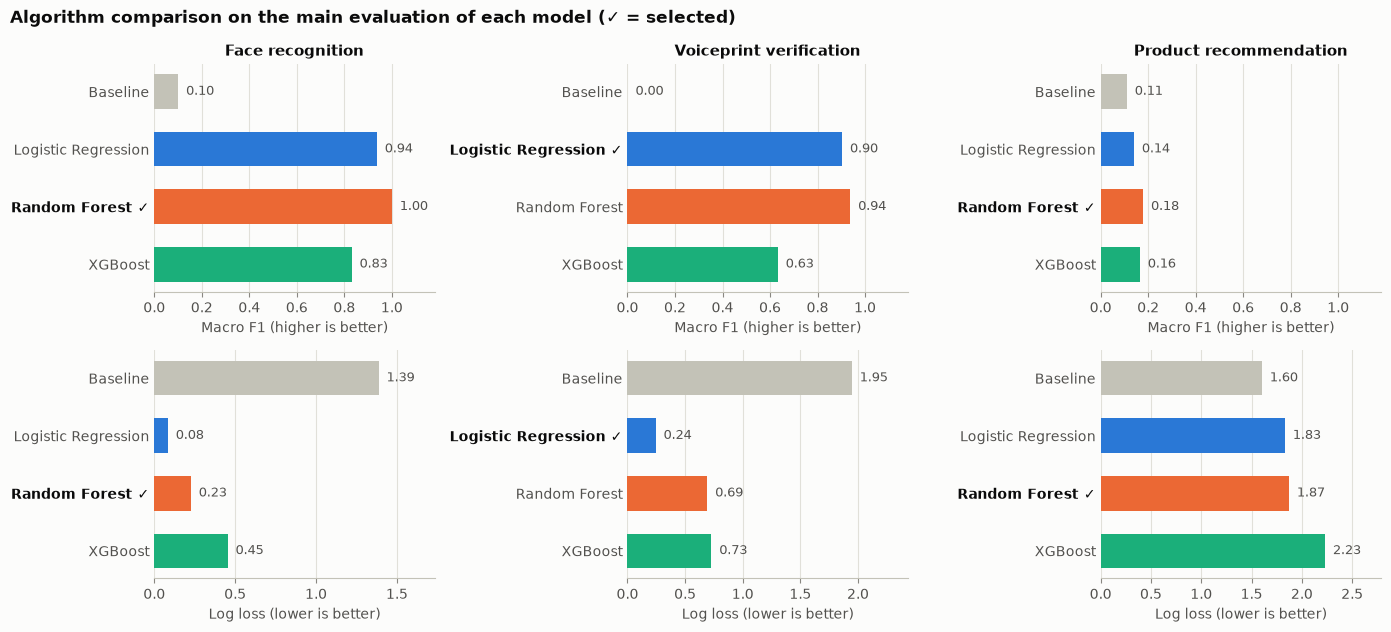

In [8]:
MAIN_EVALUATION = {
    "Face recognition": "Leave-one-expression-out CV (48 images)",
    "Voiceprint verification": "Leave-one-recording-out CV: all versions (32)",
    "Product recommendation": "Customer-grouped 5-fold CV (150 transactions)",
}
SELECTED = dict(zip(results["selected"]["model"], results["selected"]["selected_algorithm"]))
ORDER = ["Baseline (class prior)", "Logistic Regression", "Random Forest", "XGBoost"]

fig, axes = plt.subplots(2, 3, figsize=(14, 6.4))
for col, (model, evaluation) in enumerate(MAIN_EVALUATION.items()):
    subset = metrics[(metrics["model"] == model) & (metrics["evaluation"] == evaluation)].set_index("algorithm").loc[ORDER]
    for row, (metric, label, limit) in enumerate([("f1_macro", "Macro F1 (higher is better)", 1.18),
                                                  ("log_loss", "Log loss (lower is better)", None)]):
        ax = axes[row, col]
        values = subset[metric]
        ax.barh(range(len(ORDER)), values, height=0.6, color=[ALGORITHM_COLORS[a] for a in ORDER])
        for i, v in enumerate(values):
            ax.text(v, i, f"  {v:.2f}", va="center", ha="left", color=INK_2, fontsize=9)
        labels = [a + " ✓" if a == SELECTED[model] else a.replace(" (class prior)", "") for a in ORDER]
        ax.set_yticks(range(len(ORDER)), labels)
        for tick, algorithm in zip(ax.get_yticklabels(), ORDER):
            if algorithm == SELECTED[model]:
                tick.set_fontweight("bold"); tick.set_color(INK)
        ax.invert_yaxis()
        ax.set_xlim(0, limit or values.max() * 1.25)
        ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
        ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
        ax.set_xlabel(label)
        if row == 0:
            ax.set_title(model)
fig.suptitle("Algorithm comparison on the main evaluation of each model (✓ = selected)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "model_comparison.png", dpi=150)
plt.show()

The top row confirms the closed-set ranking (face and voice far above the baseline, product at baseline level); the bottom row shows calibration: Logistic Regression has the lowest log loss for face and voice, and for the product model every algorithm's log loss is *worse* than the baseline's, i.e. the models are confidently wrong about as often as they are right.

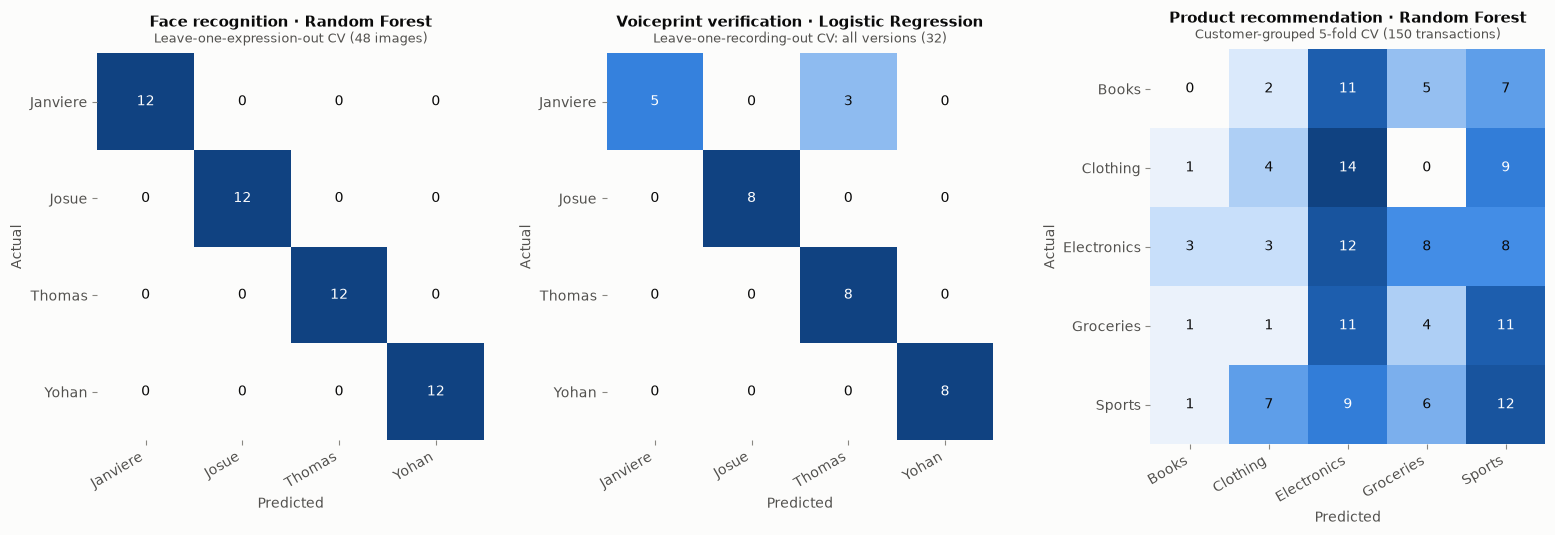

In [9]:
panels = [("face", "Face recognition"), ("voice", "Voiceprint verification"), ("product", "Product recommendation")]
fig, axes = plt.subplots(1, 3, figsize=(16, 5.4), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for ax, (key, model) in zip(axes, panels):
    r = results[key]
    tested = ~np.isnan(r["cv_proba"][:, 0])
    cm = confusion_matrix(r["y"][tested], r["cv_proba"][tested].argmax(axis=1), labels=range(len(r["classes"])))
    ax.imshow(cm, cmap=SEQUENTIAL, vmin=0, vmax=cm.max())
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10,
                    color="#ffffff" if cm[i, j] > 0.6 * cm.max() else INK)
    ax.set_xticks(range(len(r["classes"])), r["classes"], rotation=30, ha="right")
    ax.set_yticks(range(len(r["classes"])), r["classes"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
    ax.set_title(f"{model} · {SELECTED[model]}\n", fontsize=11)
    ax.text(0.5, 1.02, MAIN_EVALUATION[model], transform=ax.transAxes, ha="center", va="bottom",
            fontsize=9, color=INK_2)
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices.png", dpi=150)
plt.show()

Face: a clean diagonal, every held-out photo identified. Voice: 29 of 32 clips on the diagonal; all three errors come from a single recording (Janviere's first clip and two of its augmented versions, heard as Thomas). Their confidence (0.59–0.78) is below the 0.83 threshold, so in the real flow that attempt would be rejected rather than attributed to the wrong person. Product: predictions are scattered across all categories with no dominant diagonal, consistent with the data having no signal.

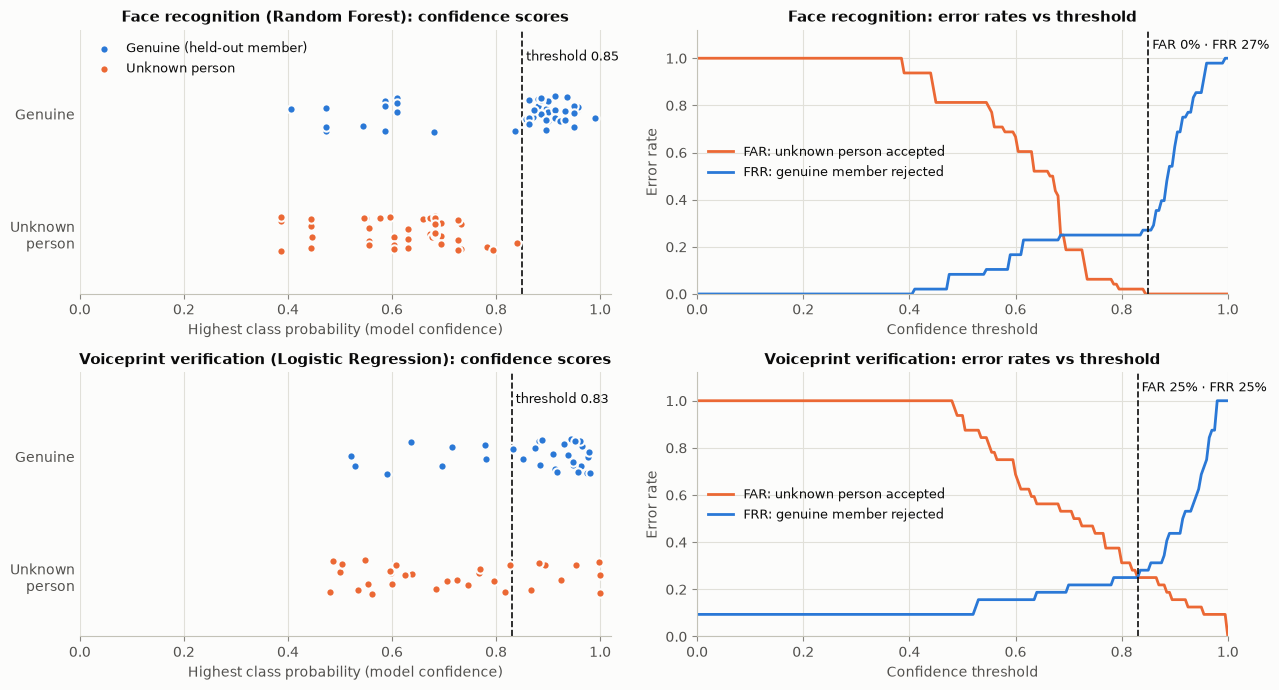

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
rng = np.random.default_rng(0)
for row, (key, model) in enumerate(panels[:2]):
    r = results[key]
    genuine = r["cv_proba"].max(axis=1)
    impostor = r["impostor_scores"]
    threshold = r["threshold"]
    table = r["threshold_table"]

    ax = axes[row, 0]
    for y_pos, scores, color, label in [(1, genuine, GENUINE_COLOR, "Genuine (held-out member)"),
                                        (0, impostor, IMPOSTOR_COLOR, "Unknown person")]:
        ax.scatter(scores, y_pos + rng.uniform(-0.15, 0.15, len(scores)), s=36, color=color,
                   edgecolor=SURFACE, linewidth=1.5, label=label, zorder=3)
    ax.axvline(threshold, color=INK, linestyle="--", linewidth=1.2)
    ax.text(threshold, 1.42, f" threshold {threshold:.2f}", color=INK, fontsize=9, va="bottom")
    ax.set_yticks([0, 1], ["Unknown\nperson", "Genuine"]); ax.set_ylim(-0.5, 1.7); ax.set_xlim(0, 1.02)
    ax.set_xlabel("Highest class probability (model confidence)")
    ax.set_title(f"{model} ({SELECTED[model]}): confidence scores")
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

    ax = axes[row, 1]
    ax.plot(table["threshold"], table["FAR"], color=IMPOSTOR_COLOR, linewidth=2, label="FAR: unknown person accepted")
    ax.plot(table["threshold"], table["FRR"], color=GENUINE_COLOR, linewidth=2, label="FRR: genuine member rejected")
    ax.axvline(threshold, color=INK, linestyle="--", linewidth=1.2)
    far = np.mean(impostor >= threshold)
    frr = np.mean(~((r["cv_proba"].argmax(axis=1) == r["y"]) & (genuine >= threshold)))
    ax.text(threshold, 1.04, f" FAR {far:.0%} · FRR {frr:.0%}", fontsize=9, color=INK)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.12)
    ax.set_xlabel("Confidence threshold"); ax.set_ylabel("Error rate")
    ax.set_title(f"{model}: error rates vs threshold")
    ax.grid(color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    ax.legend(loc="center left", fontsize=9)
axes[0, 0].legend(loc="upper left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "open_set_thresholds.png", dpi=150)
plt.show()

Left: genuine members (blue) versus people the model has never seen (orange). For the face model the two groups barely overlap, and the dashed threshold at 0.85 sits above every unknown face. For the voice model the groups overlap more, which is why some error remains on both sides. Right: lowering the threshold lets more strangers in (FAR rises), raising it turns away more genuine members (FRR rises); the selected threshold minimises the sum of the two.

## 8. Multimodal decision logic

The three models are combined exactly as in the assignment's flow (implemented in `src/inference.py`, used by the command-line demo):

1. **Face**: the face model must recognise a team member with confidence ≥ **0.85**, otherwise *ACCESS DENIED*.
2. **Product model**: the recognised member's customer profile (`data/member_customer_map.csv`) is sent to the product model; the prediction is computed but **withheld**.
3. **Voice**: the voiceprint model must identify the **same** member as the face, with confidence ≥ **0.83**, otherwise *ACCESS DENIED*.
4. Only then is the predicted product category **displayed**.

Requiring two independent factors to agree is what makes the system secure even though voice alone is a weak check: in the open-set tests no unknown face passed step 1 (FAR 0%), and an impostor would additionally have to pass the voice check (FAR 25%), so the combined false-acceptance rate is at most 0% × 25% = 0%. The price is paid by genuine users with *new* samples: they must pass both checks, so roughly 1 − (1 − 0.27)(1 − 0.25) ≈ 45% of fresh attempts would be asked to try again. More enrolment photos and recordings per member would reduce this.

Below, every combination of a member's face (neutral photo) with every member's voice (first recording) is run through the full flow:

In [11]:
artifacts = load_artifacts()
members = artifacts["face"]["classes"]
outcomes = pd.DataFrame(index=pd.Index(members, name="Face"), columns=pd.Index(members, name="Voice"), dtype=object)
for face_member in members:
    for voice_member in members:
        result = run_transaction(DATA_DIR / "images" / face_member / f"{face_member}_neutral.jpg",
                                 DATA_DIR / "audio" / voice_member / f"{voice_member}_recording1.m4a", artifacts)
        outcomes.loc[face_member, voice_member] = (f"APPROVED: {result['product']['category']}"
                                                   if result["status"] == "APPROVED" else "DENIED")
display(outcomes)

example = run_transaction(DATA_DIR / "images" / "Josue" / "Josue_neutral.jpg",
                          DATA_DIR / "audio" / "Thomas" / "Thomas_recording1.m4a", artifacts)
print("Josue's face + Thomas's voice ->", example["status"], "|", example["reason"])

Voice,Janviere,Josue,Thomas,Yohan
Face,,,,
Janviere,APPROVED: Sports,DENIED,DENIED,DENIED
Josue,DENIED,APPROVED: Clothing,DENIED,DENIED
Thomas,DENIED,DENIED,APPROVED: Books,DENIED
Yohan,DENIED,DENIED,DENIED,APPROVED: Sports


Josue's face + Thomas's voice -> ACCESS DENIED | Voice does not match Josue (closest voice: Thomas)


Only the diagonal (face and voice from the same person) is approved, and only then is the product recommendation shown; every mismatched pair is denied at the voice step with the reason. These samples were part of the training data, so their confidences are high; the open-set analysis in section 7 is the realistic estimate for new samples. Attempts by people outside the team (an unknown face and an unknown voice) are demonstrated in the command-line demo (Task 6).

## 9. Saved outputs

| File | Content |
|---|---|
| `models/face_recognition.joblib` | Random Forest, class names, feature list, threshold 0.85, evaluation metrics |
| `models/voiceprint_verification.joblib` | Logistic Regression (with scaling), class names, feature list, threshold 0.83, evaluation metrics |
| `models/product_recommendation.joblib` | Random Forest (with median imputation), class names, feature list, evaluation metrics |
| `outputs/model_metrics.csv` | Accuracy, macro F1 and log loss for every model, algorithm and evaluation |
| `outputs/open_set_thresholds.csv` | Threshold, FAR and FRR per face/voice algorithm |
| `outputs/figures/*.png` | The three figures above |

In [12]:
display(pd.read_csv(METRICS_CSV).head(8))

,model,algorithm,evaluation,accuracy,f1_macro,log_loss
0,Face recognition,Baseline (class prior),Leave-one-expression-out CV (48 images),0.2500,0.1000,1.3863
1,Face recognition,Baseline (class prior),Hold-out: surprised expression (16 images),0.2500,0.1000,1.3863
2,Face recognition,Logistic Regression,Leave-one-expression-out CV (48 images),0.9375,0.9365,0.0833
3,Face recognition,Logistic Regression,Hold-out: surprised expression (16 images),0.8125,0.7818,0.2345
4,Face recognition,Random Forest,Leave-one-expression-out CV (48 images),1.0000,1.0000,0.2253
5,Face recognition,Random Forest,Hold-out: surprised expression (16 images),1.0000,1.0000,0.3639
6,Face recognition,XGBoost,Leave-one-expression-out CV (48 images),0.8333,0.8304,0.4528
7,Face recognition,XGBoost,Hold-out: surprised expression (16 images),0.5625,0.4485,0.7085


## 10. Limitations

- **Very small datasets**: 12 photos and 8 recordings in total. Every estimate above rests on a handful of samples (e.g. FAR 25% for voice means 8 of 32 unknown clips), so the numbers indicate behaviour rather than precise rates.
- **Colour-histogram face features** capture background, lighting and clothing as much as the face itself; a stranger photographed in a similar setting to a member could be confused with them. Face-specific features (e.g. a cropped face with HOG or embeddings) would be more robust.
- **Thresholds** were chosen on simulated strangers (team members left out of training); they should be re-checked with real unauthorized samples.
- **Product data** contains no measurable relationship between customer features and product category, so the recommendation is effectively a guess; collecting behavioural data that actually differs between categories is the only fix.